In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [ ]:
class Value:
  def __init__(self, data, _children=(), _op="", label=""):
    self.data = data
    self.grad = 0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), "+")

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad

    out._backward = _backward

    return out

  def __radd__(self, other):
    return self + other


  def __sub__(self, other):
    return self + (-other)


  def __rsub__(self, other):
    return other + (-self)


  def __neg__(self):
    return self * -1


  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), "*")

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad

    out._backward = _backward

    return out

  def __rmul__(self, other):
    return self * other


  def __truediv__(self, other):
    return self * other**-1


  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float power for now"
    out = Value(self.data**other, (self,), f"**{other}")

    def _backward():
      self.grad += other * (self.data ** (other - 1)) * out.grad

    out._backward = _backward

    return out


  def tanh(self):
    n = self.data
    t = (math.exp(2*n) - 1)/(math.exp(2*n) + 1)
    out = Value(t, (self, ), "tanh")

    def _backward():
      self.grad += (1 - t**2) * out.grad

    out._backward = _backward

    return out


  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')

    def _backward():
      self.grad += out.data * out.grad # ?? exercise :)
    out._backward = _backward

    return out


  def backward(self):

    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [ ]:
a = Value(2.0)
b = 3
a / b

Value(data=0.6666666666666666)

In [ ]:
# input x1, y1
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w = x1w1 + x2w2; x1w1x2w.label = 'x1*w1 + x2*w2'
n = x1w1x2w + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

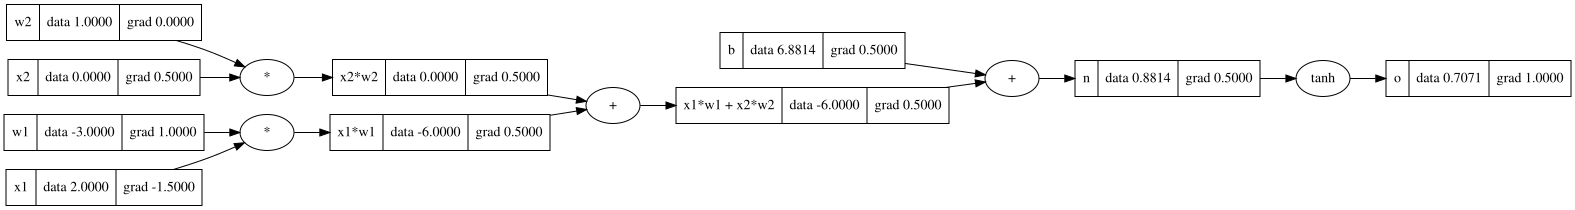

In [ ]:
draw_dot(o)

In [ ]:
# input x1, y1
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w = x1w1 + x2w2; x1w1x2w.label = 'x1*w1 + x2*w2'
n = x1w1x2w + b; n.label = 'n'
# ---

e = (2*n).exp()
o = (e -1 ) / (e + 1)

# ---
o.label = 'o'
o.backward()

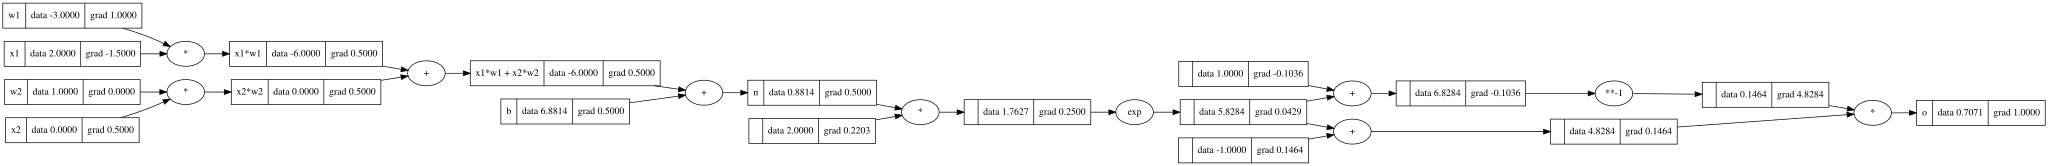

In [ ]:
draw_dot(o)

In [ ]:
import torch

x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [ ]:
class Neuron:

  def __init__(self, nin): # nin - number of inputs
    self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1, 1))


  def __call__(self, x):
    # w * x + b
    # print(list(zip(self.w, x)))

    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:

  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:

  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)

    return x


  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


In [ ]:
x = [2.0, 3.0, -1]

# n = Neuron(2)
# n = Layer(2, 3)
n = MLP(3, [4, 4, 1])

n(x)

Value(data=-0.46574771050406666)

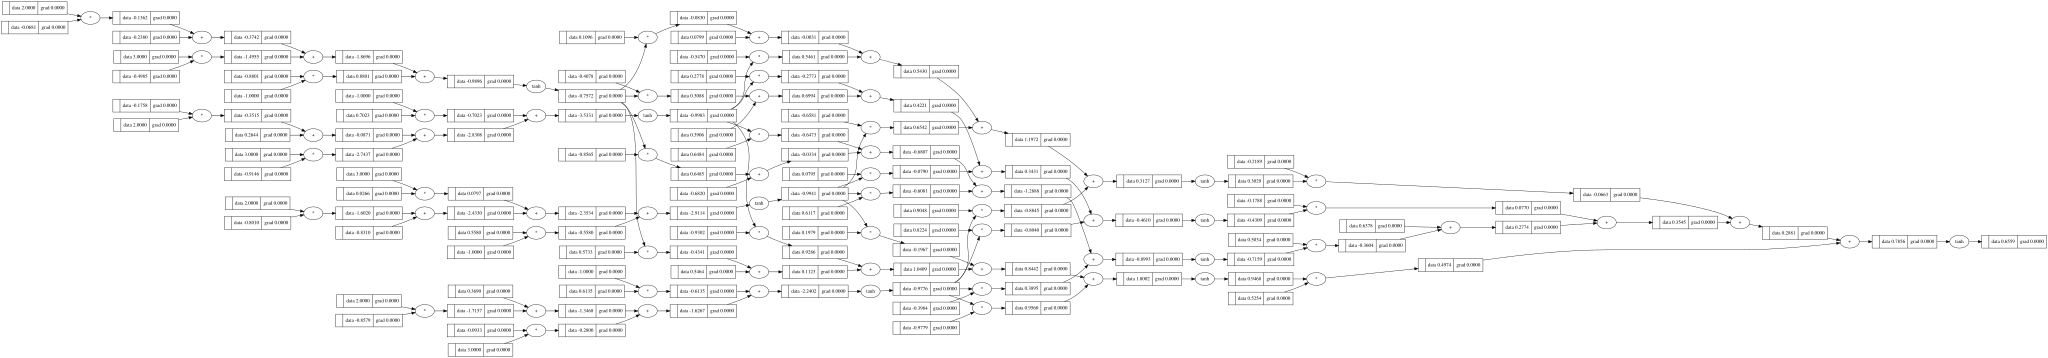

In [ ]:
draw_dot(n(x))

In [ ]:
n.layers[0].neurons[0].w[0]

Value(data=-0.06810635550682931)

In [ ]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0] # desired targets


In [ ]:
n.layers[0].neurons[0].w[0]

Value(data=-0.06810635550682931)

In [ ]:
ypred = [n(x) for x in xs]

loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=4.06174504313138)

In [ ]:
loss.backward()

In [ ]:
n.layers[0].neurons[0].w[0]

Value(data=-0.06810635550682931)

In [ ]:
n.parameters()

[Value(data=-0.06810635550682931),
 Value(data=-0.498488625229347),
 Value(data=-0.8800559590003447),
 Value(data=-0.2379536713618866),
 Value(data=-0.1757642640735313),
 Value(data=-0.9145512650283316),
 Value(data=0.7023144272949291),
 Value(data=0.2644290120758108),
 Value(data=-0.8009816391298401),
 Value(data=0.026553173779248374),
 Value(data=0.5580407420079994),
 Value(data=-0.831047098837943),
 Value(data=-0.8578621201158667),
 Value(data=-0.09331832402232254),
 Value(data=0.6134684814469997),
 Value(data=0.3689667969114261),
 Value(data=-0.8565172529240557),
 Value(data=0.6483821601174211),
 Value(data=0.611677984499537),
 Value(data=-0.3984478357306447),
 Value(data=-0.6819802375917734),
 Value(data=-0.40778508009879055),
 Value(data=0.2778085351869872),
 Value(data=0.079478605973486),
 Value(data=0.8224468694005334),
 Value(data=0.39062887856247563),
 Value(data=0.10961699825722127),
 Value(data=-0.5469878626819666),
 Value(data=-0.6581252679475444),
 Value(data=0.9048079397

In [ ]:
learning_rate = 0.01

for p in n.parameters():
  p.data -= learning_rate * p.grad

In [ ]:
n.layers[0].neurons[0].w[0]

Value(data=-0.06392346096429617)

In [ ]:
ypred = [n(x) for x in xs]

loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=3.79358445927279)

In [ ]:
for k in range(50):

  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

  # backward pass
  for p in n.parameters():
    p.grad = 0
  loss.backward()

  #update
  for p in n.parameters():
    p.data -= 0.05 * p.grad

  print(k, loss.data)


0 0.0019526714627488846
1 0.0019456889679245752
2 0.001938754873470247
3 0.0019318686836207323
4 0.0019250299093151071
5 0.0019182380680841842
6 0.001911492683940359
7 0.0019047932872695247
8 0.0018981394147251783
9 0.0018915306091247311
10 0.0018849664193477235
11 0.0018784464002360465
12 0.001871970112496283
13 0.001865537122603774
14 0.0018591470027086185
15 0.0018527993305435717
16 0.0018464936893336128
17 0.0018402296677073227
18 0.0018340068596099611
19 0.0018278248642182445
20 0.0018216832858565968
21 0.0018155817339152683
22 0.001809519822769752
23 0.0018034971717018752
24 0.001797513404822325
25 0.001791568150994665
26 0.0017856610437607325
27 0.001779791721267486
28 0.001773959826195159
29 0.0017681650056868429
30 0.0017624069112792545
31 0.00175668519883485
32 0.001750999528475234
33 0.0017453495645156775
34 0.0017397349754009364
35 0.0017341554336422556
36 0.0017286106157553488
37 0.0017231002021997205
38 0.0017176238773189867
39 0.0017121813292822368
40 0.00170677225002654

In [ ]:
ypred

[Value(data=0.9842802069377715),
 Value(data=-0.9842689022135298),
 Value(data=-0.9761418157127216),
 Value(data=0.9755919007985533)]